In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import sys
sys.path.append('../')
from utils import *

## Single Run

In [2]:
#critical deltas
epsilon_value = 0.1
lambda_value = 0.2
P, R, T, S = 0.2, 0.8, 1, 0
c2 = ((2*P) - (epsilon_value *P) - (epsilon_value *R) - (2 *S) + (epsilon_value *S) + (epsilon_value *T))/((-1 + epsilon_value) *((-2 *P) + (2 *epsilon_value *P) + (2 *S) - (epsilon_value *S) - (epsilon_value *T)))
c1 = (-epsilon_value *P + 2 *R - epsilon_value *R + epsilon_value *S - 2 *T + epsilon_value *T)/((-1 + epsilon_value)* (-2 *P + 2 *epsilon_value *P - epsilon_value *S + 2 *T - epsilon_value *T))
print(f'critical delta 1 is {c1} and critical delta 2 is {c2}')

critical delta 1 is 0.2886002886002886 and critical delta 2 is 0.9661835748792271


In [3]:
M_value = 100
delta_value = 0.98

In [4]:
algo = Algorithm(e=epsilon_value, lambda_val=lambda_value, 
                 alpha=0.05, delta=delta_value,
                 random_uniform=False, tolerance=1e-7, 
                 M=M_value, verbose=False)
q1_history_per_sample, q2_history_per_sample = algo.run()
dfs_1  = convert_dict_to_mean_df(q1_history_per_sample, mean= False)
dfs_2  = convert_dict_to_mean_df(q2_history_per_sample, mean= False)
strategy_played_1 = {}
strategy_played_2 = {}

# Iterate over the dataframe rows
for i in range(len(dfs_1)):
    last_1 = dfs_1[i].iloc[-1]  # Get the last row using iloc (optimized)
    last_2 = dfs_2[i].iloc[-1]  # Same for second dataframe

    # Define conditions for both players
    GT_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
    AD_1 = (last_1['Q1'] < last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
    AC_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] > last_1['Q4'])

    GT_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
    AD_2 = (last_2['Q1'] < last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
    AC_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] > last_2['Q4'])

    # Assign strategy for both players
    strategy_map = {
        AD_1: 1,  # Always Defecting
        GT_1: 2,  # Grim Trigger
        AC_1: 3,  # Always Cooperating
    }

    # Handle strategy for player 1 and player 2
    for player, strategy in [(AD_1, strategy_map), (GT_1, strategy_map), (AC_1, strategy_map)]:
        if player:
            strategy_played_1[i] = strategy[player]
            break  # Once a strategy is found, break the loop to avoid multiple assignments

    for player, strategy in [(AD_2, strategy_map), (GT_2, strategy_map), (AC_2, strategy_map)]:
        if player:
            strategy_played_2[i] = strategy[player]
            break  # Once a strategy is found, break the loop to avoid multiple assignments

# Convert strategy_played_1 and strategy_played_2 dictionaries to DataFrames
df_strategy_1 = pd.DataFrame(list(strategy_played_1.items()), columns=['Index', 'Strategy_1'])
df_strategy_2 = pd.DataFrame(list(strategy_played_2.items()), columns=['Index', 'Strategy_2'])

# Merge the two DataFrames on 'Index'
df_merged = pd.merge(df_strategy_1, df_strategy_2, on='Index')

# Optionally, set 'Index' as the DataFrame index (if you need it)
df_merged.set_index('Index', inplace=True)
# Count how many times Strategy_1 and Strategy_2 are different
count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()

# Display the result
print(f"Number of times Strategy_1 and Strategy_2 are different: {count_diff}")
# Count how many times both Strategy_1 and Strategy_2 have the value 1
P_AD = ((df_merged['Strategy_1'] == 1) & (df_merged['Strategy_2'] == 1)).sum()/M_value

# Count how many times both Strategy_1 and Strategy_2 have the value 2
P_GT = ((df_merged['Strategy_1'] == 2) & (df_merged['Strategy_2'] == 2)).sum()/M_value

# Display the results
print(f"P_AD: {P_AD}")
print(f"P_GT: {P_GT}")
# Count how many times Strategy_1 and Strategy_2 are different
count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()/M_value

# Display the result
print(f"Number of times Strategy_1 and Strategy_2 are different (NO CONVERGENCE): {count_diff}")


KeyboardInterrupt: 

In [18]:
P_AC = (1-(P_AD+P_GT)).round(4)
P_AC

np.float64(0.17)

## Simulation

In [14]:
# For tracking progress
M_value = 100
alpha_values = [0.05,0.1,0.2]
lambda_values = [0.05,0.1,0.2]
delta_values = [0.5,0.6,0.7]  # 1000 equally spaced values from 0 to 0.999
epsilon_values = [0.05,0.1,0.2]  # 1000 equally spaced values from 0 to 0.99
random_uniform_values = [False]

# Store results
results = []

# Generate all parameter combinations
parameter_combinations = list(itertools.product(alpha_values, lambda_values, epsilon_values, delta_values, random_uniform_values))

# Iterate through each parameter combination with tqdm progress bar
for alpha, lambda_val, e, delta, random_uniform in tqdm(parameter_combinations, desc="Processing combinations"):
    # Initialize the algorithm with the current parameter combination
    algo = Algorithm(e=e, lambda_val=lambda_val, 
                     alpha=alpha, delta=delta,
                     random_uniform=random_uniform, tolerance=1e-5, 
                     M=M_value, verbose=False)

    # Run the algorithm
    q1_history_per_sample, q2_history_per_sample = algo.run()

    # Convert results to dataframes
    dfs_1 = convert_dict_to_mean_df(q1_history_per_sample, mean=False)
    dfs_2 = convert_dict_to_mean_df(q2_history_per_sample, mean=False)

    # Initialize strategies played
    strategy_played_1 = {}
    strategy_played_2 = {}

    # Iterate over the dataframe rows
    for i in range(len(dfs_1)):
        last_1 = dfs_1[i].iloc[-1]  # Get the last row using iloc
        last_2 = dfs_2[i].iloc[-1]

        # Define conditions for both players
        GT_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
        AD_1 = (last_1['Q1'] < last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
        AC_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] > last_1['Q4'])

        GT_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
        AD_2 = (last_2['Q1'] < last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
        AC_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] > last_2['Q4'])

        # Assign strategy for both players
        strategy_map = {
            AD_1: 1,  # Always Defecting
            GT_1: 2,  # Grim Trigger
            AC_1: 3,  # Always Cooperating
        }

        for player, strategy in [(AD_1, strategy_map), (GT_1, strategy_map), (AC_1, strategy_map)]:
            if player:
                strategy_played_1[i] = strategy[player]
                break

        for player, strategy in [(AD_2, strategy_map), (GT_2, strategy_map), (AC_2, strategy_map)]:
            if player:
                strategy_played_2[i] = strategy[player]
                break

    # Convert strategy_played_1 and strategy_played_2 dictionaries to DataFrames
    df_strategy_1 = pd.DataFrame(list(strategy_played_1.items()), columns=['Index', 'Strategy_1'])
    df_strategy_2 = pd.DataFrame(list(strategy_played_2.items()), columns=['Index', 'Strategy_2'])

    # Merge the two DataFrames on 'Index'
    df_merged = pd.merge(df_strategy_1, df_strategy_2, on='Index')

    # Optionally, set 'Index' as the DataFrame index (if you need it)
    df_merged.set_index('Index', inplace=True)

    # Count how many times Strategy_1 and Strategy_2 are different
    count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()

    # Count how many times both Strategy_1 and Strategy_2 have the value 1
    P_AD = ((df_merged['Strategy_1'] == 1) & (df_merged['Strategy_2'] == 1)).sum() / M_value

    # Count how many times both Strategy_1 and Strategy_2 have the value 2
    P_GT = ((df_merged['Strategy_1'] == 2) & (df_merged['Strategy_2'] == 2)).sum() / M_value

    # Store results for this parameter combination
    results.append({
        'alpha': alpha,
        'lambda': lambda_val,
        'e': e,
        'delta': delta,
        'random_uniform': random_uniform,
        'P_AD': P_AD,
        'P_GT': P_GT,
        'nonconv': count_diff
    })

# Optionally, save results to a file
results_df = pd.DataFrame(results)
results_df.to_csv("results.csv", index=False)


Processing combinations: 100%|██████████| 81/81 [02:09<00:00,  1.60s/it]


## Analysis

In [2]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df

,alpha,lambda,e,delta,random_uniform,P_AD,P_GT,nonconv
0,0.01,0.01,0.010000,0.050833,False,1.0,0.0,0
1,0.01,0.01,0.010000,0.010000,False,1.0,0.0,0
2,0.01,0.01,0.010000,0.132500,False,1.0,0.0,0
3,0.01,0.01,0.010000,0.214167,False,1.0,0.0,0
4,0.01,0.01,0.010000,0.295833,False,0.8,0.2,0
...,...,...,...,...,...,...,...,...
390620,1.00,0.99,0.800000,0.867500,False,1.0,0.0,0
390621,1.00,0.99,0.800000,0.908333,False,1.0,0.0,0
390622,1.00,0.99,0.800000,0.949167,False,1.0,0.0,0
390623,1.00,0.99,0.767083,0.990000,False,1.0,0.0,0


In [3]:
df[(df['P_AD'] + df['P_GT'] != 1) & (df['nonconv'] == 0)]


,alpha,lambda,e,delta,random_uniform,P_AD,P_GT,nonconv
210207,0.54625,0.418333,0.075833,0.99,False,0.90,0.08,0
255906,0.67000,0.336667,0.075833,0.99,False,0.98,0.00,0


<Axes: >

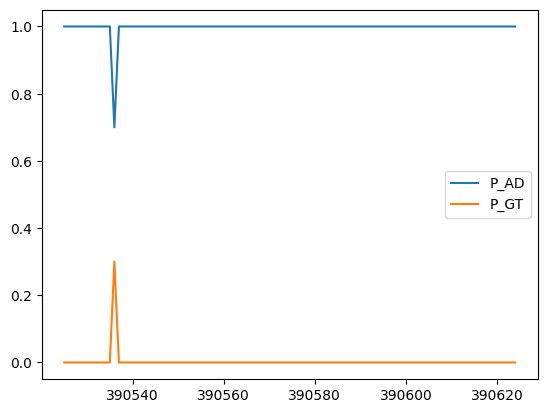

In [4]:
df[['P_AD', 'P_GT']].tail(100).plot()

In [5]:
df['delta'] = df['delta'].round(3)
df['e'] = df['e'].round(3)
df['lambda'] = df['lambda'].round(3)
df['alpha'] = df['alpha'].round(3)


In [6]:
columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
pair_combinations = list(itertools.combinations(columns, 2))

# Display the pair combinations
print(pair_combinations)

[('delta', 'e'), ('delta', 'lambda'), ('delta', 'alpha'), ('e', 'lambda'), ('e', 'alpha'), ('lambda', 'alpha')]


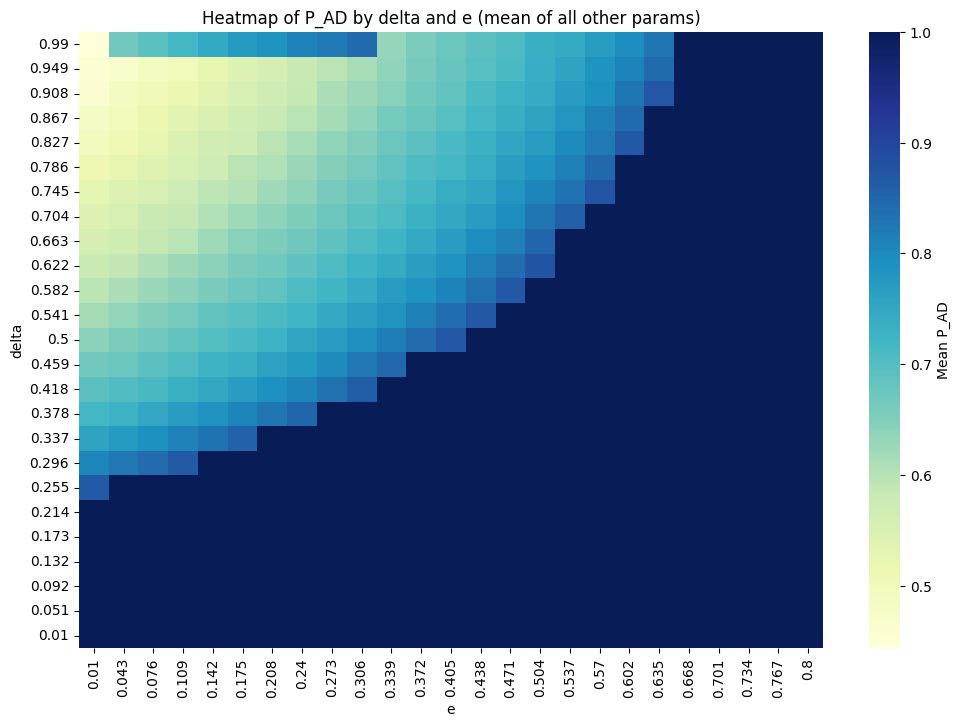

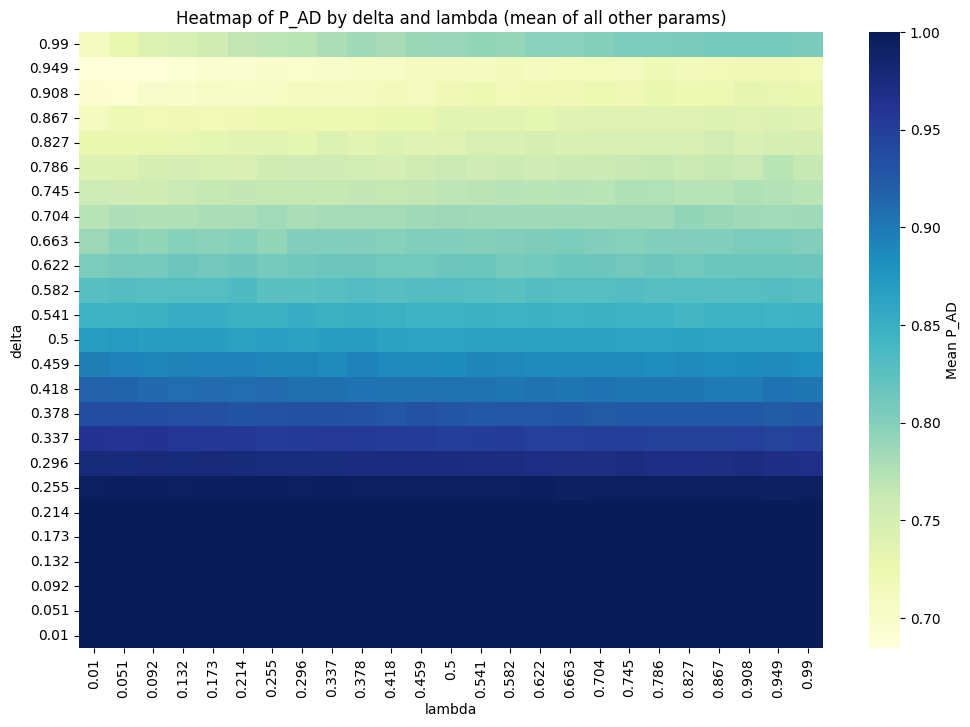

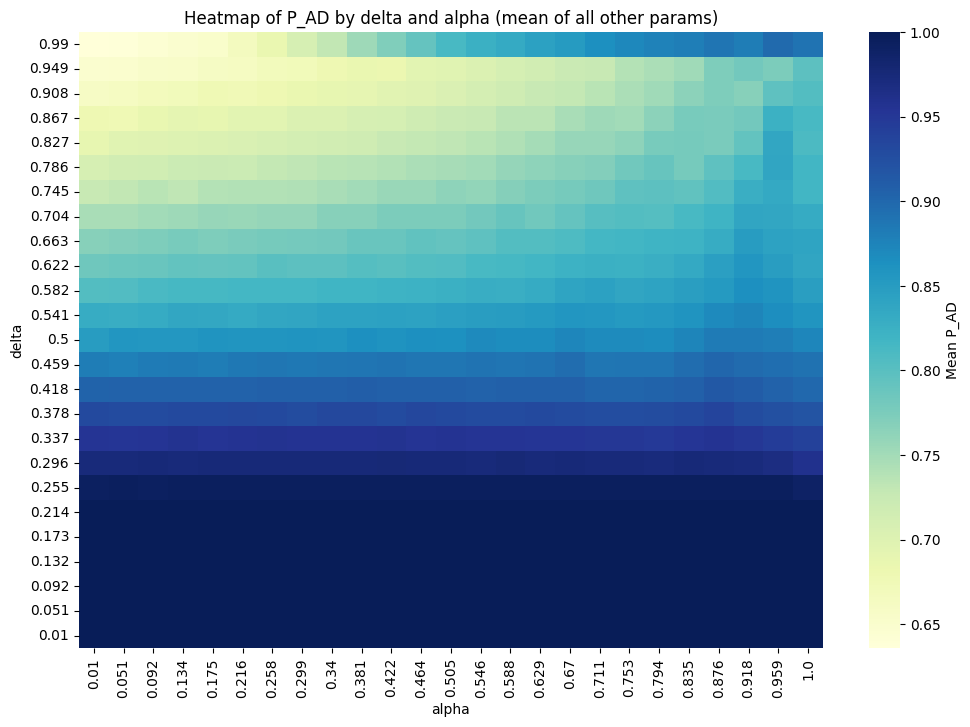

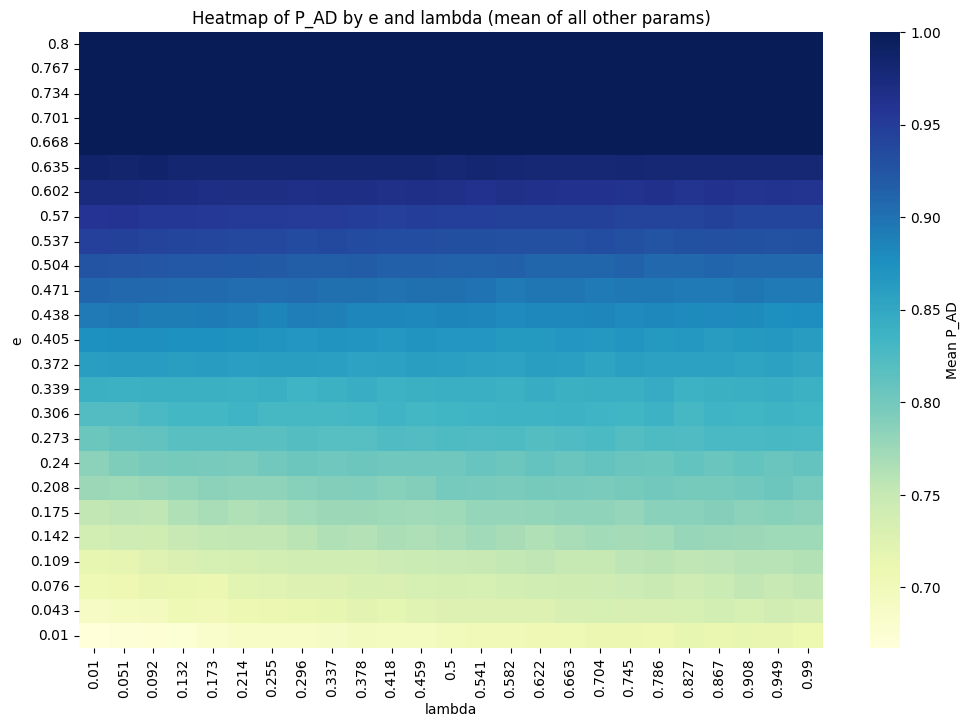

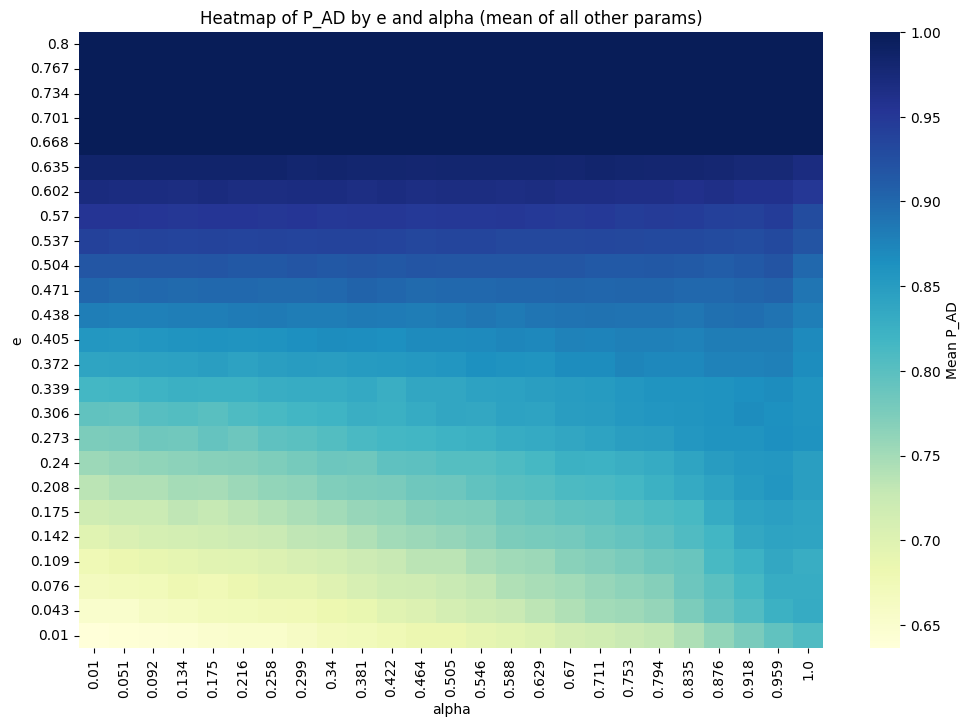

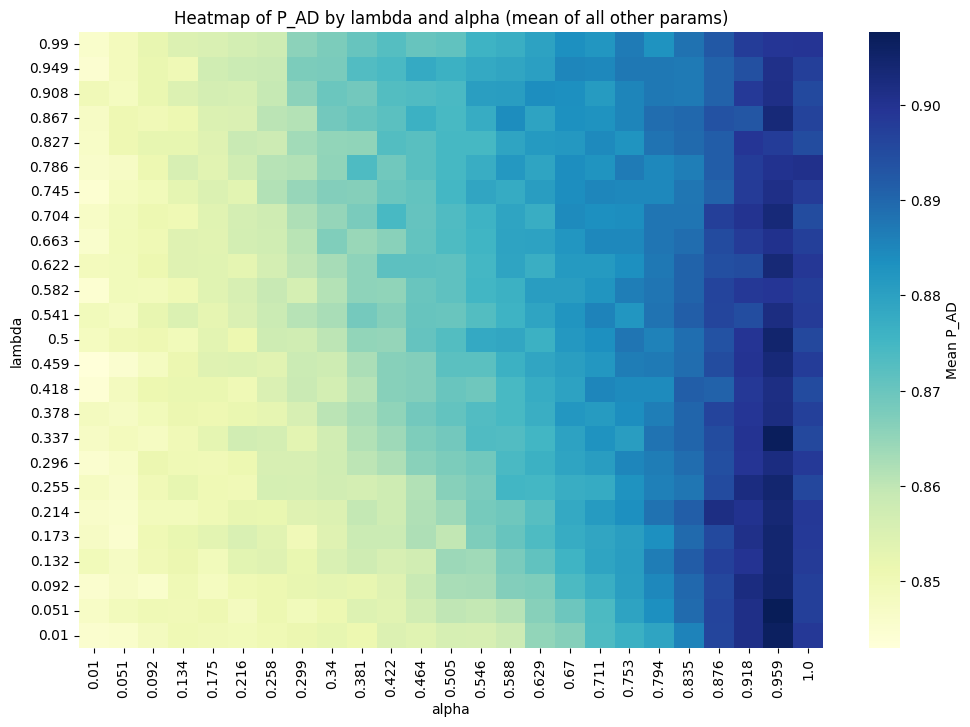

In [7]:
heatmap_mean(df, 'delta', 'e', 'P_AD')
heatmap_mean(df, 'delta', 'lambda','P_AD')
heatmap_mean(df, 'delta', 'alpha', 'P_AD')
heatmap_mean(df, 'e', 'lambda', 'P_AD')
heatmap_mean(df, 'e', 'alpha', 'P_AD')
heatmap_mean(df, 'lambda', 'alpha', 'P_AD')


In [8]:
#here insert code for improving the heatmap where delta is 0.99


In [9]:
for i in df.columns:
    print('                           ')
    print(f'{str(i)}: {df[i].unique()}')

                           
alpha: [0.01  0.051 0.092 0.134 0.175 0.216 0.258 0.299 0.34  0.381 0.422 0.464
 0.505 0.546 0.588 0.629 0.67  0.711 0.753 0.794 0.835 0.876 0.918 0.959
 1.   ]
                           
lambda: [0.01  0.051 0.092 0.132 0.173 0.214 0.255 0.296 0.337 0.378 0.418 0.459
 0.5   0.541 0.582 0.622 0.663 0.704 0.745 0.786 0.827 0.867 0.908 0.949
 0.99 ]
                           
e: [0.01  0.043 0.076 0.109 0.142 0.175 0.208 0.24  0.273 0.306 0.339 0.372
 0.405 0.438 0.471 0.504 0.537 0.57  0.602 0.635 0.668 0.701 0.734 0.767
 0.8  ]
                           
delta: [0.051 0.01  0.132 0.214 0.296 0.378 0.092 0.173 0.255 0.337 0.418 0.459
 0.5   0.541 0.582 0.622 0.663 0.704 0.745 0.786 0.827 0.867 0.908 0.949
 0.99 ]
                           
random_uniform: [False]
                           
P_AD: [1.   0.8  0.72 0.82 0.78 0.74 0.62 0.48 0.46 0.54 0.38 0.4  0.42 0.32
 0.36 0.28 0.6  0.56 0.44 0.52 0.3  0.34 0.88 0.7  0.58 0.5  0.76 0.92
 0.68 0.86 0.84 0.9

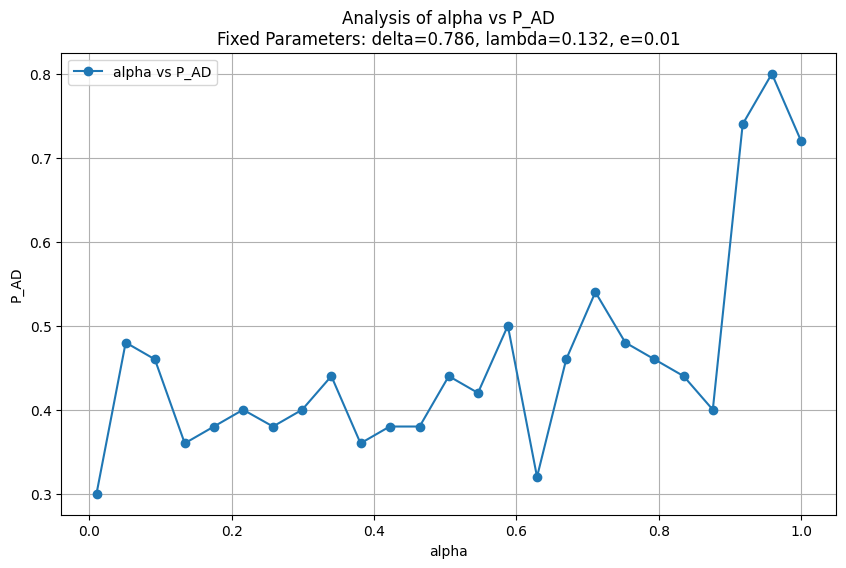

In [10]:
plot_analysis(
    df=df, 
    fixed_vars={'delta': 0.786, 'lambda': 0.132, 'e': 0.01}, 
    x_var='alpha'
)

#increasing #samples how this plot changes (xvar = lambda) 'delta': 0.517 -> GT || separetely low delta -> AD
#introduce M as parameter to see how lambda is changing on differnt Ms (try single exps)

#run latin hypercube

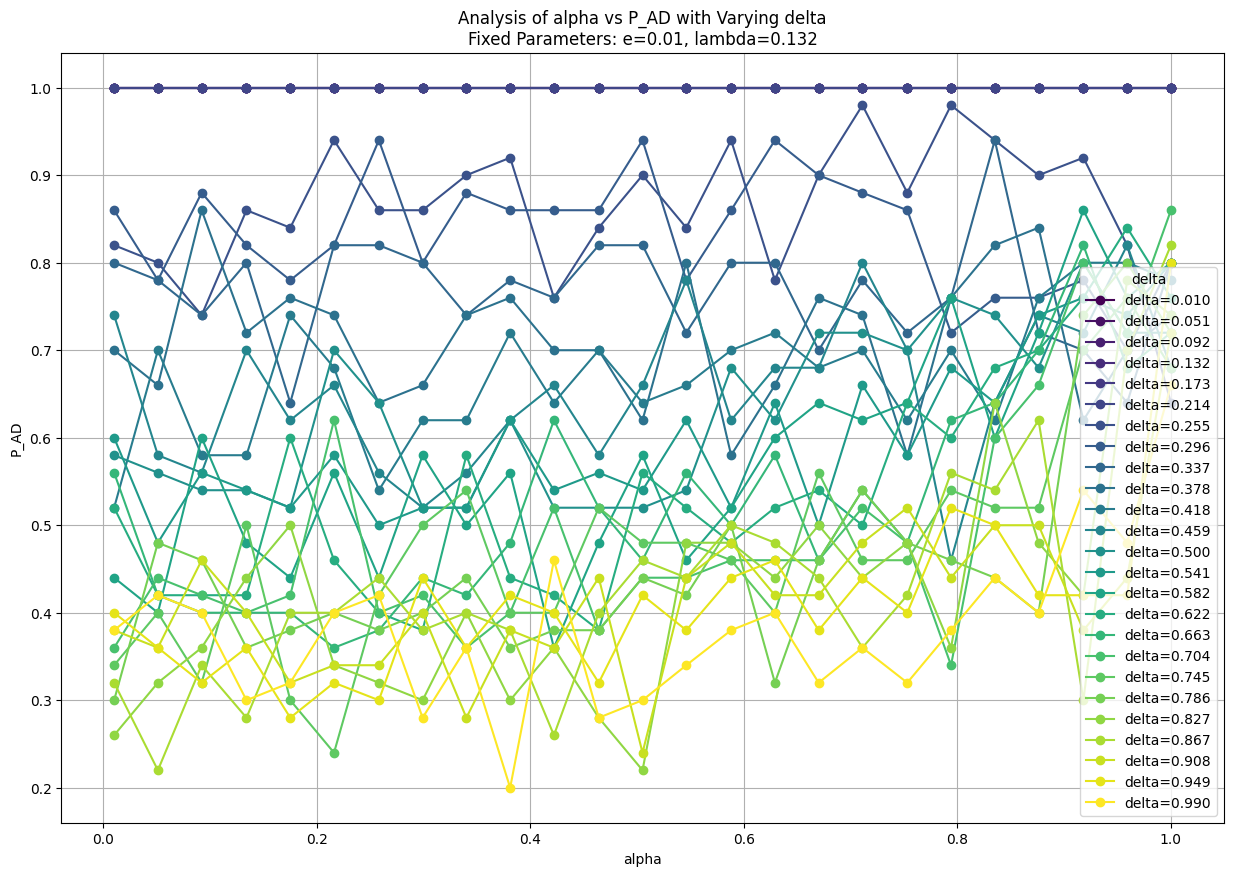

In [11]:
plot_analysis_multiple_lines(
    df=df, 
    fixed_vars={'e': 0.01, 'lambda': 0.132}, 
    x_var='alpha', 
    varying_var='delta'
)


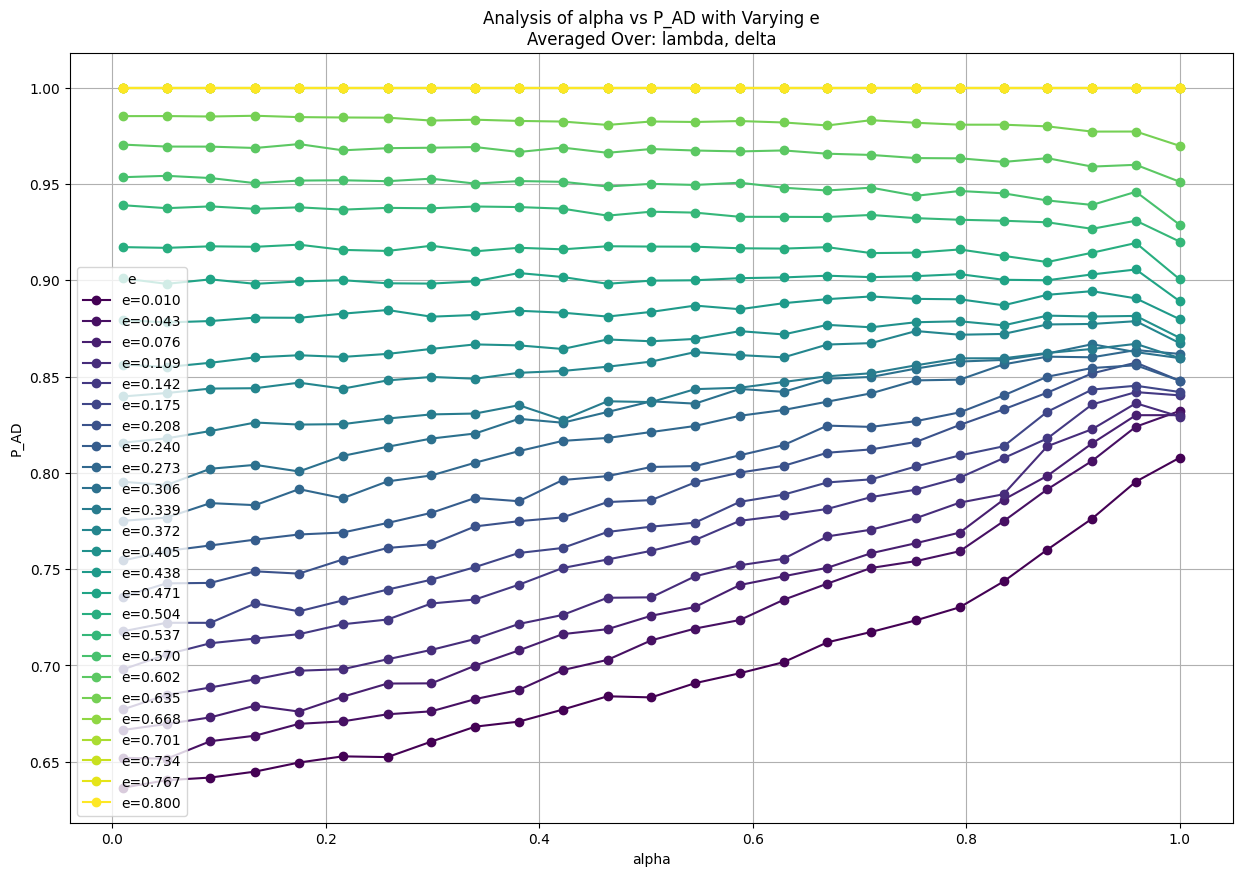

In [12]:
plot_analysis_average_and_vary(
    df=df, 
    averaging_vars=['lambda', 'delta'], 
    x_var='alpha', 
    varying_var='e'
)
